# 07 — Trapped-ion idling is dephasing, and only an X-basis memory sees it

**Narrative point 9.** Quantinuum's emulator models idle noise as Z only: a linear term
(probability γt) and a quadratic term (sin²(ωt/2), twirled). A Z-basis memory decodes on
Z checks, which commute with Z errors: it cannot see idling at all, so it shows no
trade-off. The interval study therefore needs |+⟩ logical states and X checks.

This notebook runs a small demonstration through the package (d = 3, Stim, seconds).
`MemorySpec` refuses the blind combination unless it is marked as a deliberate control
(`allow_invisible_noise=True`).

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
from qec_timing.backends.stim_circuit import StimCircuitBackend
from qec_timing.codes.surface import RotatedSurfaceCode
from qec_timing.noise.circuit import CircuitNoise, IdleNoise
from qec_timing.schedule import Schedule
from qec_timing.spec import MemorySpec
from qec_timing.store import Store
from qec_timing.studies import runs

store, backend = Store(Path("..") / "store"), StimCircuitBackend()
gates = dict(p1=9e-5, p2=5e-3, p_meas=4.7e-3, p_init=1.9e-4)        # H2 ratios, scaled x4.76
out = {}
for basis in ("X", "Z"):
    for label, idle in (("dephasing on", IdleNoise(gamma=1.5e-3)), ("dephasing off", IdleNoise())):
        noise = CircuitNoise(**gates, idle=idle, placement="uniform")
        pts = []
        for dt in (1, 2, 4, 8, 16):
            R_ = int(round(48 / dt))
            spec = MemorySpec(RotatedSurfaceCode(3), basis, Schedule.rounds(float(dt), R_), noise,
                              50_000, 4000 + dt, allow_invisible_noise=(basis == "Z"))
            ids, f, n = runs.failures(store, backend, spec)
            pts.append((dt, f / n))
        out[(basis, label)] = pts
for k, v in out.items():
    print(k, [f"{p:.4f}" for _, p in v])

('X', 'dephasing on') ['0.1533', '0.1027', '0.0780', '0.0689', '0.0718']
('X', 'dephasing off') ['0.1142', '0.0609', '0.0330', '0.0153', '0.0072']
('Z', 'dephasing on') ['0.1100', '0.0585', '0.0296', '0.0158', '0.0080']
('Z', 'dephasing off') ['0.1107', '0.0577', '0.0303', '0.0160', '0.0074']


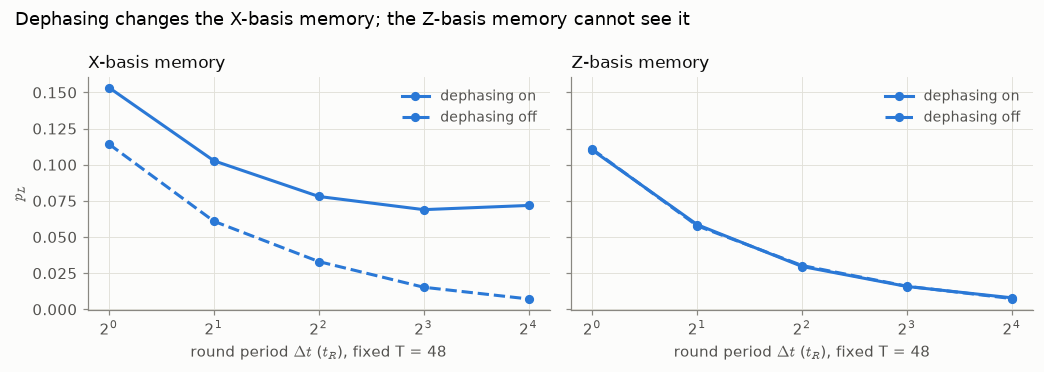

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True)
for ax, basis in zip(axes, ("X", "Z")):
    for label, ls in (("dephasing on", "-"), ("dephasing off", "--")):
        dt, pl = zip(*out[(basis, label)])
        ax.plot(dt, pl, ls, marker="o", color=P.SERIES[0], label=label)
    ax.legend(loc="upper right", fontsize=9)
    ax.set_xscale("log", base=2); ax.set_xlabel(r"round period $\Delta t$ ($t_R$), fixed T = 48")
    ax.set_title(f"{basis}-basis memory", loc="left")
axes[0].set_ylabel(r"$p_L$")
fig.suptitle("Dephasing changes the X-basis memory; the Z-basis memory cannot see it", x=0.01, ha="left")
fig.tight_layout()
P.save(fig, "07_dephasing_needs_x_basis_1")

**Reading.**
- *Measured:* turning dephasing on raises the X-basis logical error and grows with the
  interval; in the Z basis the two curves coincide within sampling noise. The original
  notebook 07 measured the same at larger scale: at most 2.1σ in Z against up to 304σ in X.
- *Consequence:* results from Z-basis memories (the paper's bit-flip model, notebook 03) say
  nothing about trapped-ion idling; every circuit-level and hardware study here uses X.